# Code from Feb 2026

## imports

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib import cm
from statsmodels.regression.mixed_linear_model import MixedLM

## data preparation

### load dataset

In [2]:
# load results
df = pd.read_parquet("/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/models_and_figures/big_df.parquet")
df['dataset'] = 'MH_dreadd'

# drop columns without values
df = df.drop(columns=['steps', 'quantiles', 'mrequantiles', 'tauquantiles', 'description'])
df = df[~df['area'].isin(['CA3-CA2', 'CA2-CA1', 'DEEP'])]

### filter dataset
we only want linear track data on days where we have it for pre and post CA2-muting

#### linear track

In [51]:
# specific filtering: only linear track data of those days, where it was recorded pre and post 

# Group by animal-day combinations
grouped = df.groupby(['animal', 'day'], observed=False)

# only include linear track data
df = df[df['task'].str.contains('lt', na=False)]

# Keep only animal-day combinations with both 'pre' and 'post' treatment
valid_groups = grouped.apply(lambda x: ('pre' in x['treatment'].values) and ('post' in x['treatment'].values))
valid_groups = valid_groups[valid_groups].index  # Only keep True indices

df = df.set_index(['animal', 'day'])
valid_groups = valid_groups.intersection(df.index)
df = df.loc[valid_groups].reset_index()

# Update grouped after filtering
grouped = df.groupby(['animal', 'day'])

/tmp/ipykernel_497298/2633828687.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  valid_groups = grouped.apply(lambda x: ('pre' in x['treatment'].values) and ('post' in x['treatment'].values))
/tmp/ipykernel_497298/2633828687.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = df.groupby(['animal', 'day'])


#### sleep

In [3]:
# specific filtering: only sleep data of those days, where it was recorded pre and post 

# Group by animal-day combinations
grouped = df.groupby(['animal', 'day'], observed=False)

# only include linear track data
df = df[df['task'].str.contains('sleep', na=False)]

# Keep only animal-day combinations with both 'pre' and 'post' treatment
valid_groups = grouped.apply(lambda x: ('pre' in x['treatment'].values) and ('post' in x['treatment'].values))
valid_groups = valid_groups[valid_groups].index  # Only keep True indices

df = df.set_index(['animal', 'day'])
valid_groups = valid_groups.intersection(df.index)
df = df.loc[valid_groups].reset_index()

# Update grouped after filtering
grouped = df.groupby(['animal', 'day'])

/tmp/ipykernel_1069152/3215892836.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  valid_groups = grouped.apply(lambda x: ('pre' in x['treatment'].values) and ('post' in x['treatment'].values))
/tmp/ipykernel_1069152/3215892836.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = df.groupby(['animal', 'day'])


### display dataframe

In [7]:
print(f"\nNumber of animal-day groups: {grouped.ngroups}")
print("\nGroup sizes:")
print(grouped.size())
# Display basic information about the dataframe
print("Shape:", df.shape)
print("\nFirst few rows:")
print(df.head())
print("\nData types:")
print(df.dtypes)


# Generate a list of all animal-day-task combinations
animal_day_task_combinations = df[['animal', 'day', 'task', 'treatment']].drop_duplicates().values.tolist()
print(f"\nTotal unique animal-day-task-treatment combinations: {len(animal_day_task_combinations)}")
print("\nAnimal-day-task-treatment combinations:")
for combo in animal_day_task_combinations:
    print(combo)



Number of animal-day groups: 153

Group sizes:
animal     day  task    treatment  area
model1216  d10  sleep1  pre        CA1     13
                                   CA2     13
                                   CA3     13
                sleep2  post       CA1     13
                                   CA2     13
                                           ..
model572   d18  sleep1  pre        CA2     26
                sleep2  post       CA1     15
                                   CA2     15
                sleep3  post       CA1     21
                                   CA2     21
Length: 153, dtype: int64
Shape: (3024, 16)

First few rows:
      animal  day                                               popt  \
0  model1216  d10  [391.0356143083164, 0.025410079547595048, 0.00...   
1  model1216  d10  [43.54195332608099, 0.04171097395023707, 0.003...   
2  model1216  d10  [245.71441647986782, 0.09539045128224491, -0.0...   
3  model1216  d10  [111.29932537849949, 0.134612783775208

### compute average tau values for combinations

In [4]:
# Remove all unused categories in grouped
grouped = df.groupby(['animal', 'day', 'task', 'treatment', 'area'], observed=True)
avg_tau_per_combo = grouped['tau'].mean().reset_index()
avg_tau_per_combo['activity'] = grouped['activity'].mean().reset_index()['activity']

#avg_tau_per_combo


### plot

#### tau

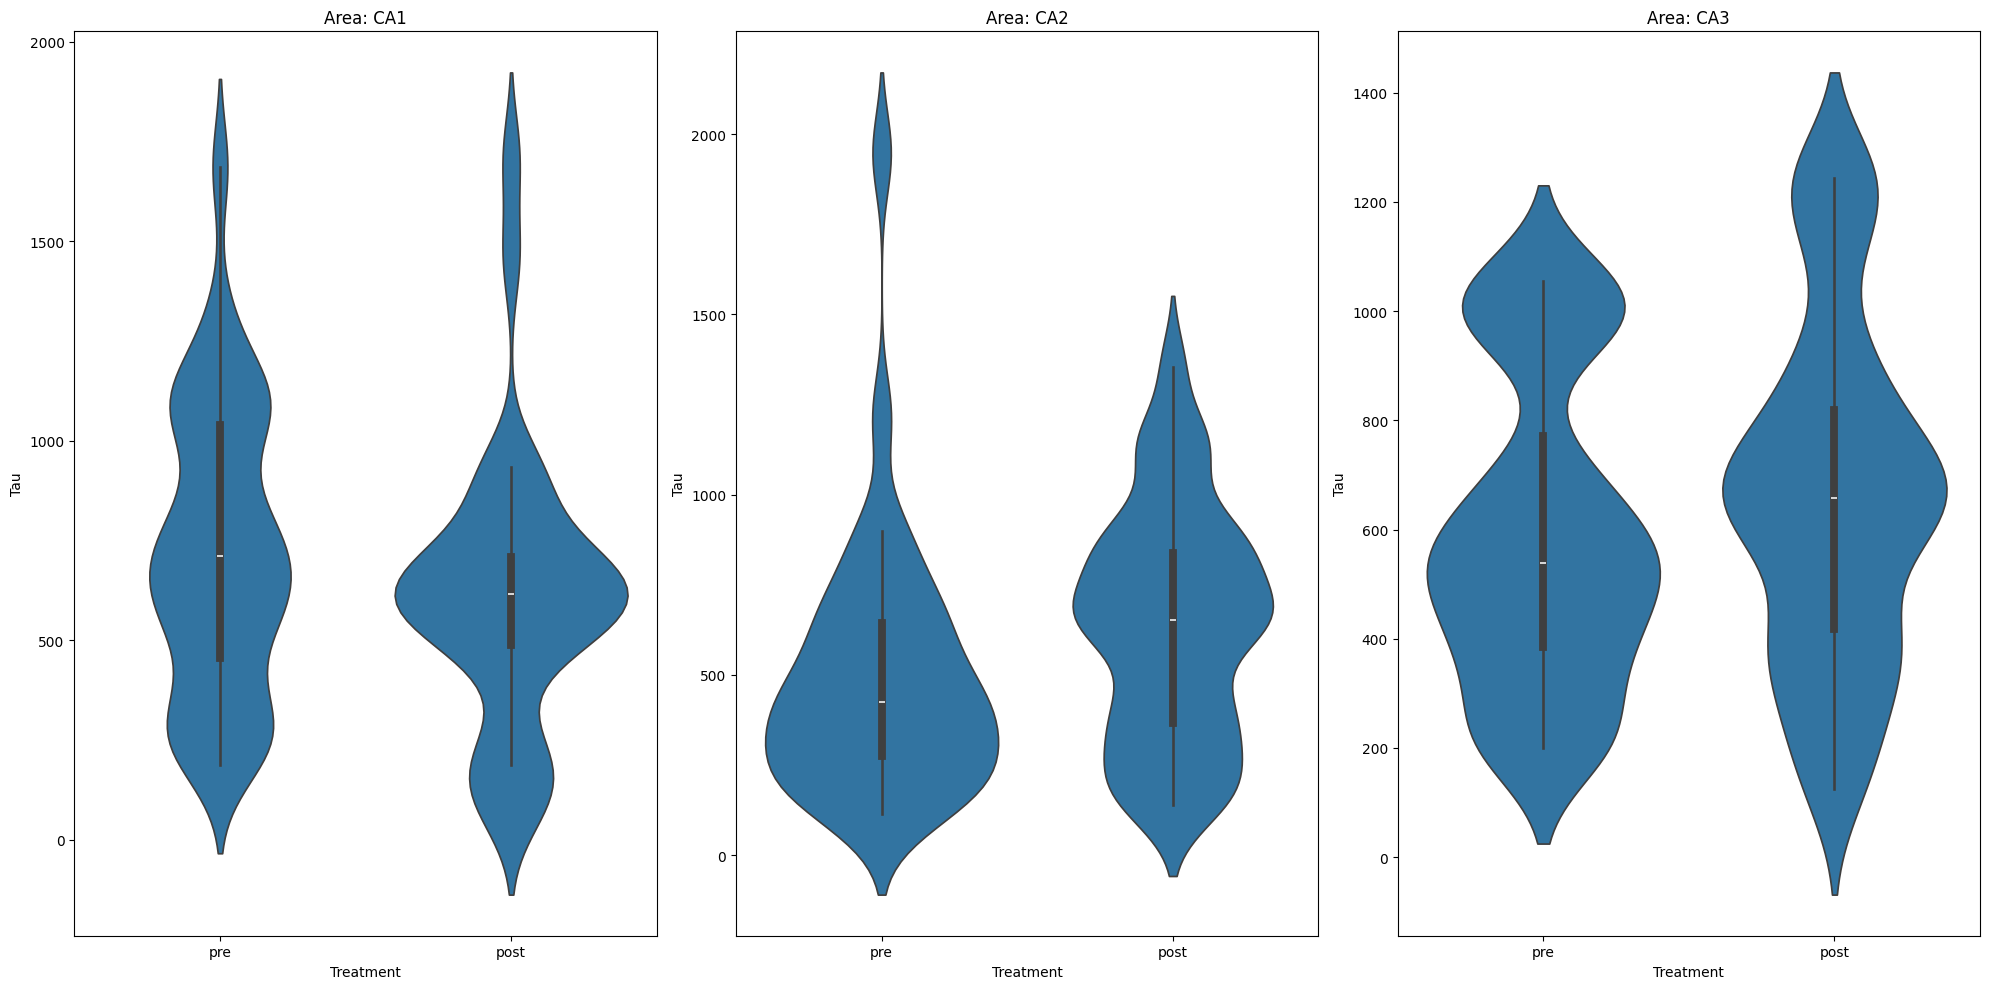

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 10))
areas = ['CA1', 'CA2', 'CA3']

for idx, area in enumerate(sorted(areas)):
    data_area = avg_tau_per_combo[avg_tau_per_combo['area'] == area]
    sns.violinplot(
        data=data_area,
        x='treatment',
        y='tau',
        ax=axes[idx],
        bw_method=0.3,
        order=['pre', 'post']
    )
    axes[idx].set_title(f'Area: {area}')
    axes[idx].set_ylabel('Tau')
    axes[idx].set_xlabel('Treatment')

plt.tight_layout()
plt.show()

#### activity

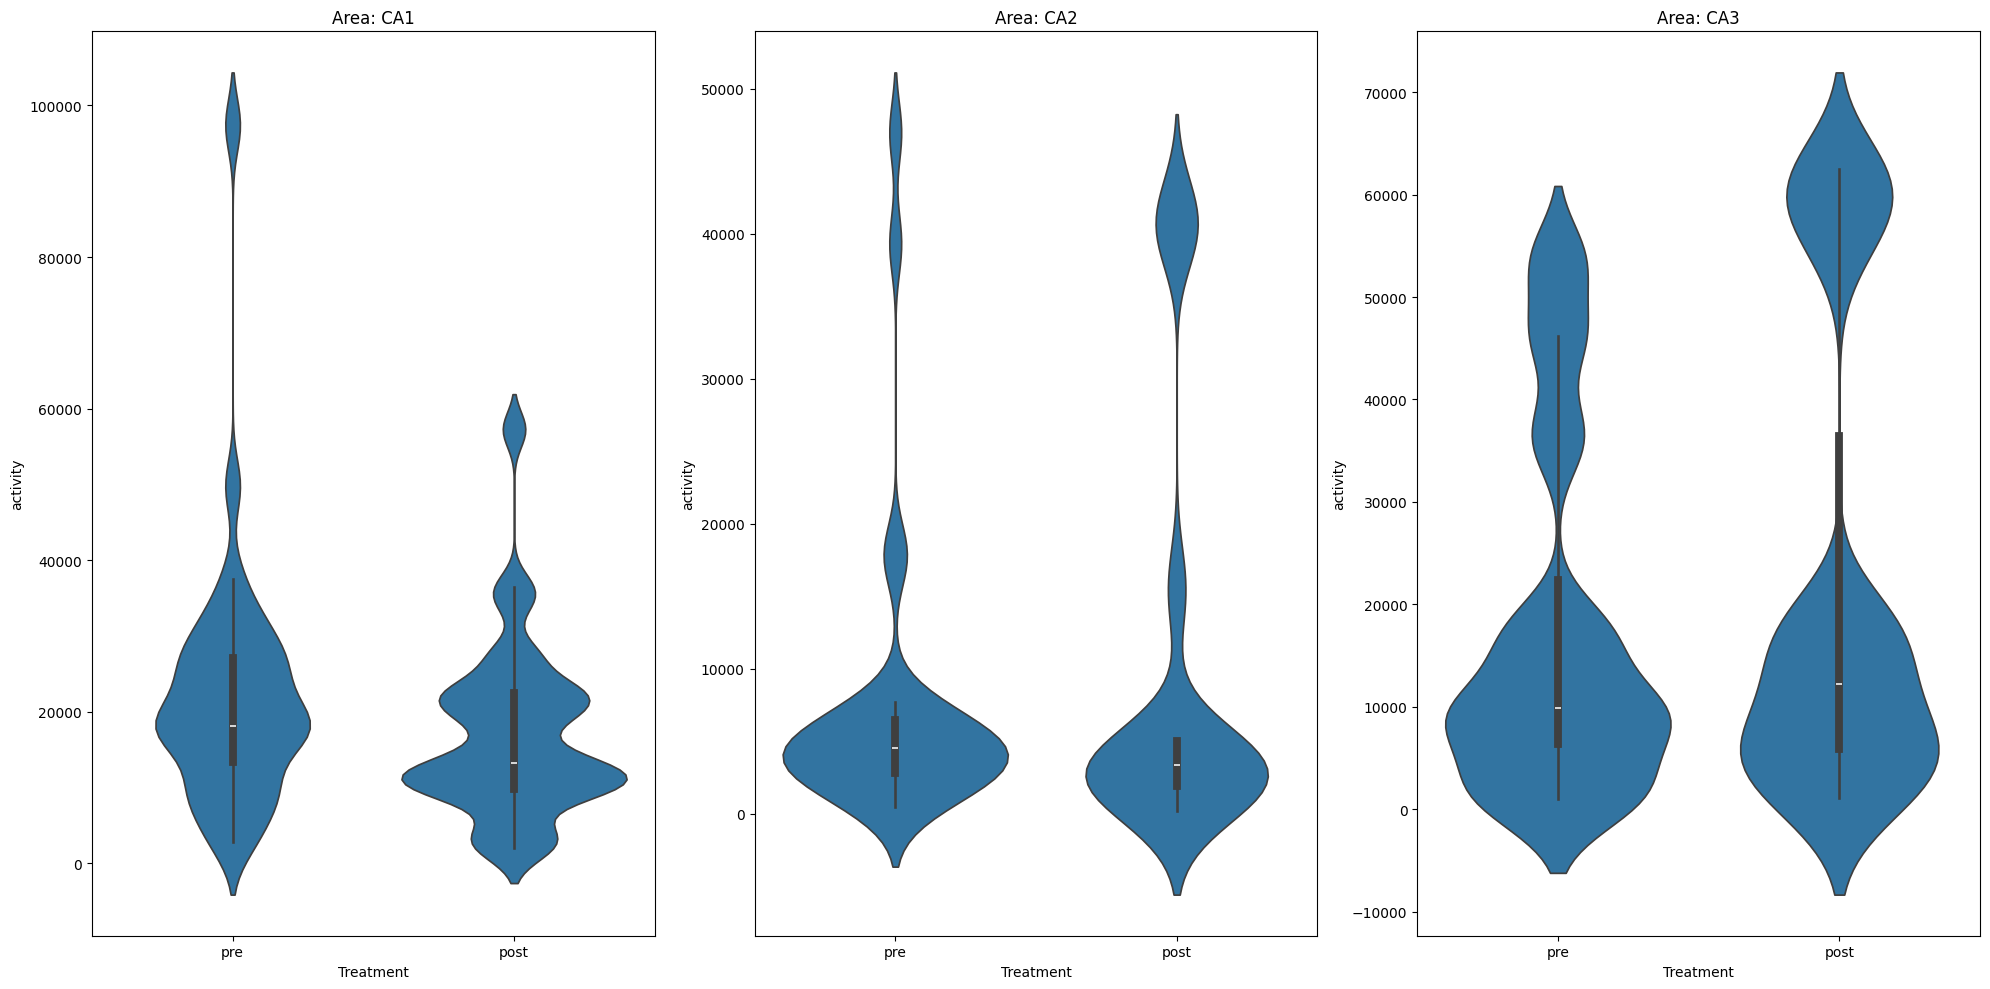

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(20, 10))
areas = ['CA1', 'CA2', 'CA3']

for idx, area in enumerate(sorted(areas)):
    data_area = avg_tau_per_combo[avg_tau_per_combo['area'] == area]
    sns.violinplot(data=data_area, x='treatment', y='activity', ax=axes[idx], bw_method=0.2, order=['pre', 'post'])
    axes[idx].set_title(f'Area: {area}')
    axes[idx].set_ylabel('activity')
    axes[idx].set_xlabel('Treatment')

plt.tight_layout()
plt.show()

### ratios

#### compute

In [58]:
# Compute ratios of post/pre for each animal-day-area combination
ratios_list = []

for (animal, day, area), group in avg_tau_per_combo.groupby(['animal', 'day', 'area'], observed = True):
    pre_data = group[group['treatment'] == 'pre']
    post_data = group[group['treatment'] == 'post']
    
    if len(pre_data) > 0 and len(post_data) > 0:
    
        tau_ratio = post_data['tau'].values[0] / pre_data['tau'].values[0]
        activity_ratio = post_data['activity'].values[0] / pre_data['activity'].values[0]
        
        ratios_list.append({
            'animal': animal,
            'day': day,
            'area': area,
            'tau_ratio': tau_ratio,
            'activity_ratio': activity_ratio
        })

ratios_df = pd.DataFrame(ratios_list)

#### plot ratios for tau

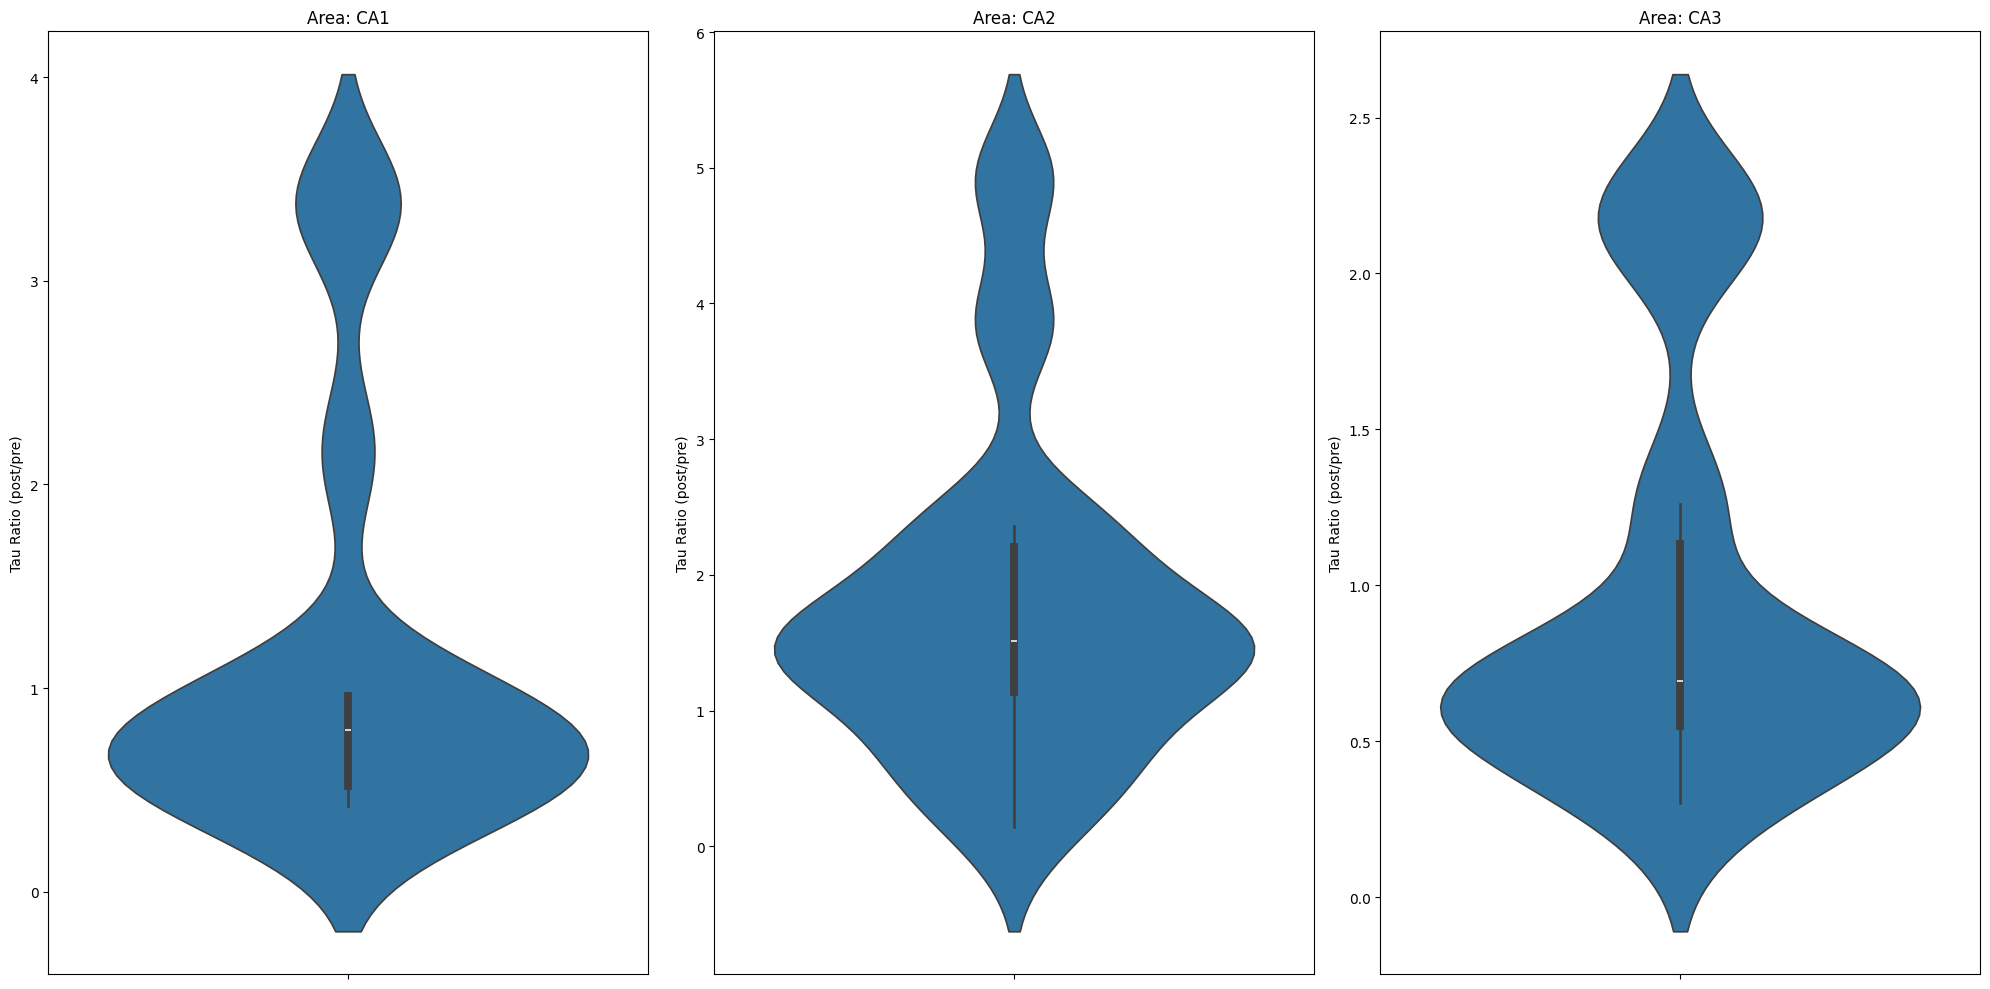

In [59]:
fig, axes = plt.subplots(1, 3, figsize=(20, 10))
areas = ['CA1', 'CA2', 'CA3']

for idx, area in enumerate(sorted(areas)):
    data_area = ratios_df[ratios_df['area'] == area]
    sns.violinplot(
        data=data_area,
        y='tau_ratio',
        ax=axes[idx],
        bw_method=0.3
    )
    axes[idx].set_title(f'Area: {area}')
    axes[idx].set_ylabel('Tau Ratio (post/pre)')

plt.tight_layout()
plt.show()

#### plot ratios for activity

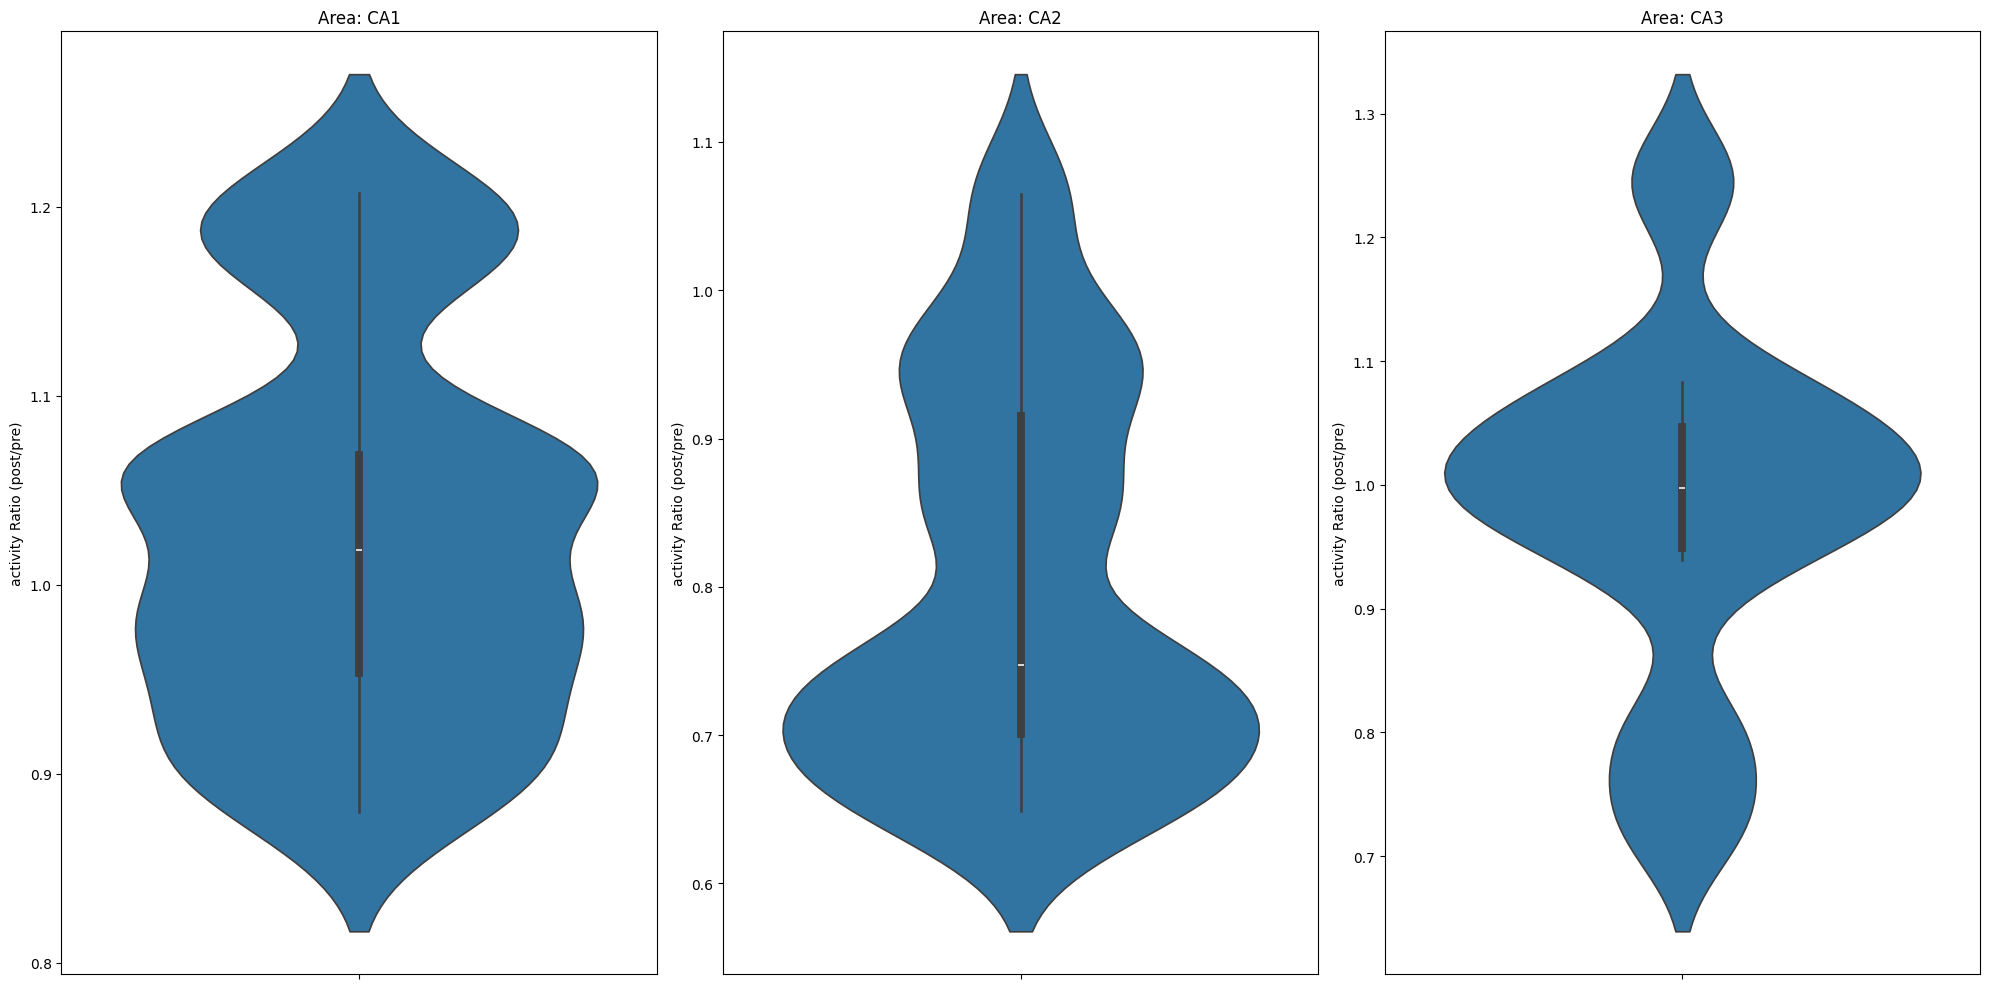

In [60]:
fig, axes = plt.subplots(1, 3, figsize=(20, 10))
areas = ['CA1', 'CA2', 'CA3']

for idx, area in enumerate(sorted(areas)):
    data_area = ratios_df[ratios_df['area'] == area]
    sns.violinplot(
        data=data_area,
        y='activity_ratio',
        ax=axes[idx],
        bw_method=0.3
    )
    axes[idx].set_title(f'Area: {area}')
    axes[idx].set_ylabel('activity Ratio (post/pre)')

plt.tight_layout()
plt.show()